# Credit Card Fraud Detection — End-to-End ML Project

**Goal:** build and evaluate a leakage-aware baseline model on the public Kaggle credit-card fraud dataset.

**Important:** this is an educational benchmark, not a production fraud decision system. Do not use the model to approve/decline real transactions.

## How to run
1. Run cells from top to bottom in Google Colab.
2. Upload `creditcard.csv` when prompted. Download it from [Kaggle](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud/data) first.
3. Keep the dataset private to your runtime; do not commit it to GitHub.
4. Metrics are generated by the run. No results are hard-coded in this notebook.

In [1]:
# Colab has these libraries pre-installed. We restrict upgrades to avoid dependency conflicts.
# If you need to force-install specific compatible versions, uncomment below:
# %pip install "pandas<2.3.0" "numpy<2.3.0" scikit-learn matplotlib seaborn
print("Using pre-installed Colab dependencies to prevent Numpy ABI conflicts.")

Using pre-installed Colab dependencies to prevent Numpy ABI conflicts.


In [2]:
import io
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, roc_auc_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    precision_recall_curve, PrecisionRecallDisplay
)

RANDOM_STATE = 42
pd.set_option('display.max_columns', 40)
print('Libraries loaded. Random state:', RANDOM_STATE)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Libraries loaded. Random state: 42


## 1. Load the dataset

Upload the Kaggle CSV. If you already placed it in the current Colab runtime at `/content/creditcard.csv`, the upload dialog is skipped.

In [5]:
import os
import kagglehub
import pandas as pd

DATA_PATH = '/content/creditcard.csv'

# Download latest version of the dataset
path = kagglehub.dataset_download("mlg-ulb/creditcardfraud")
print("Path to dataset files:", path)

# Load the CSV file into the df variable
csv_file_path = os.path.join(path, 'creditcard.csv')
df = pd.read_csv(csv_file_path)

print('Shape:', df.shape)
display(df.head())

Using Colab cache for faster access to the 'creditcardfraud' dataset.
Path to dataset files: /kaggle/input/creditcardfraud
Shape: (284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11,V12,V13,V14,V15,V16,V17,V18,V19,V20,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,0.090794,-0.551600,-0.617801,-0.991390,-0.311169,1.468177,-0.470401,0.207971,0.025791,0.403993,0.251412,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,-0.166974,1.612727,1.065235,0.489095,-0.143772,0.635558,0.463917,-0.114805,-0.183361,-0.145783,-0.069083,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,0.207643,0.624501,0.066084,0.717293,-0.165946,2.345865,-2.890083,1.109969,-0.121359,-2.261857,0.524980,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,-0.054952,-0.226487,0.178228,0.507757,-0.287924,-0.631418,-1.059647,-0.684093,1.965775,-1.232622,-0.208038,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,0.753074,-0.822843,0.538196,1.345852,-1.119670,0.175121,-0.451449,-0.237033,-0.038195,0.803487,0.408542,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2. Validate data and inspect class imbalance

We check the schema and target labels before modeling. The dataset has anonymized `V1`–`V28` features plus `Time`, `Amount`, and `Class`.

Missing values by column (top 10):


,missing_count
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


Exact duplicate rows: 1081


,count,percentage
Class,,
Legitimate (0),284315,99.8273
Fraud (1),492,0.1727


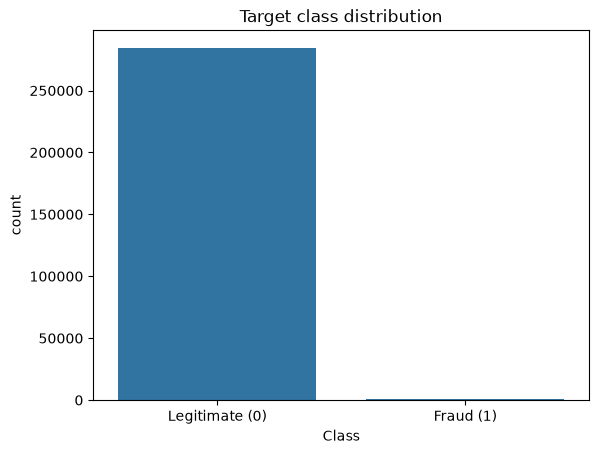

Fraud prevalence: 0.1727%


In [6]:
required_columns = {'Time', 'Amount', 'Class'} | {f'V{i}' for i in range(1, 29)}
missing_columns = required_columns - set(df.columns)
if missing_columns:
    raise ValueError(f'Missing required columns: {sorted(missing_columns)}')
if df['Class'].isna().any():
    raise ValueError('Target column Class contains missing values.')
if not set(df['Class'].unique()).issubset({0, 1}):
    raise ValueError('Class must contain only 0 (legitimate) and 1 (fraud).')

print('Missing values by column (top 10):')
display(df.isna().sum().sort_values(ascending=False).head(10).to_frame('missing_count'))
print('Exact duplicate rows:', int(df.duplicated().sum()))
class_counts = df['Class'].value_counts().sort_index()
class_rates = df['Class'].value_counts(normalize=True).sort_index() * 100
imbalance = pd.DataFrame({'count': class_counts, 'percentage': class_rates.round(4)})
display(imbalance.rename(index={0:'Legitimate (0)', 1:'Fraud (1)'}))

ax = sns.countplot(data=df, x='Class')
ax.set_title('Target class distribution')
ax.set_xticks([0, 1], ['Legitimate (0)', 'Fraud (1)'])
plt.show()
print(f'Fraud prevalence: {df["Class"].mean():.4%}')

## 3. Exploratory data analysis

Inspect transaction amount and time by class. These visualizations are descriptive, not proof of causation.

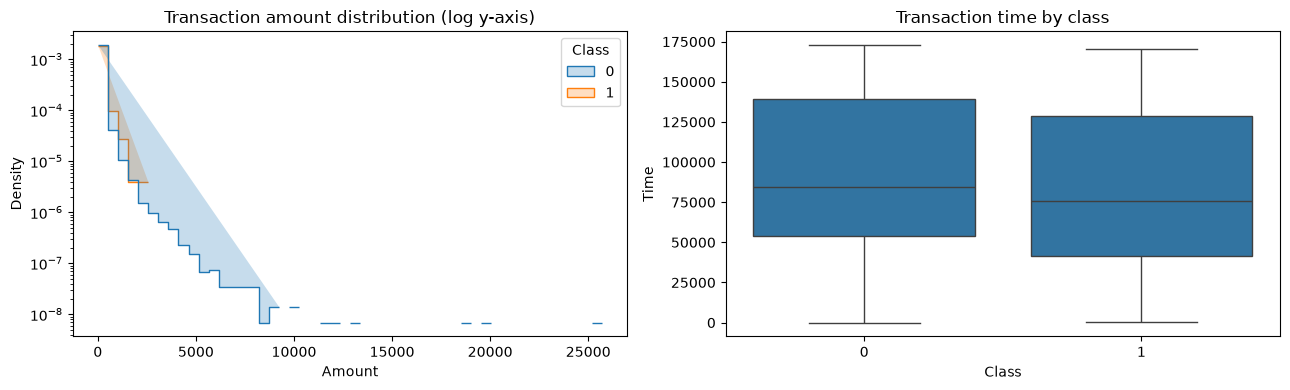

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x='Amount', hue='Class', bins=50, stat='density', common_norm=False,
             element='step', log_scale=(False, True), ax=axes[0])
axes[0].set_title('Transaction amount distribution (log y-axis)')
sns.boxplot(data=df, x='Class', y='Time', ax=axes[1], showfliers=False)
axes[1].set_title('Transaction time by class')
plt.tight_layout()
plt.show()

## 4. Create train, validation, and test splits

We split before fitting any preprocessing or model. Stratification preserves the rare-class proportion in each partition. The test set is held back until the threshold and modeling choices are finalized.

In [8]:
target = 'Class'
X = df.drop(columns=[target]).copy()
y = df[target].astype('int8').copy()

# 60% train, 20% validation, 20% test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=RANDOM_STATE
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE
)

split_summary = pd.DataFrame({
    'rows': [len(y_train), len(y_valid), len(y_test)],
    'fraud_count': [int(y_train.sum()), int(y_valid.sum()), int(y_test.sum())],
    'fraud_rate_pct': [100*y_train.mean(), 100*y_valid.mean(), 100*y_test.mean()]
}, index=['train', 'validation', 'test'])
display(split_summary.round(4))
assert set(X_train.index).isdisjoint(X_valid.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_valid.index).isdisjoint(X_test.index)
print('No overlapping row indices across splits.')

,rows,fraud_count,fraud_rate_pct
train,170884,295,0.1726
validation,56961,98,0.1720
test,56962,99,0.1738


No overlapping row indices across splits.


## 5. Establish a simple baseline

A majority-class classifier predicts every transaction as legitimate. It will have high accuracy on this dataset but zero recall for fraud, illustrating why accuracy alone is misleading.

In [9]:
dummy = DummyClassifier(strategy='most_frequent')
dummy.fit(X_train, y_train)
dummy_pred = dummy.predict(X_valid)
print('Majority-class validation accuracy:', round(float((dummy_pred == y_valid).mean()), 6))
print('Majority-class validation fraud recall:', round(float(recall_score(y_valid, dummy_pred, zero_division=0)), 6))

Majority-class validation accuracy: 0.99828
Majority-class validation fraud recall: 0.0


## 6. Train a leakage-aware logistic regression baseline

`Time` and `Amount` are standardized inside a scikit-learn pipeline, so the scaler is fitted only on training data. The anonymized `V1`–`V28` features are passed through as supplied. `class_weight='balanced'` is a baseline strategy for class imbalance, not a guarantee of optimal performance.

In [10]:
scale_columns = ['Time', 'Amount']
preprocessor = ColumnTransformer(
    transformers=[('scale_numeric', StandardScaler(), scale_columns)],
    remainder='passthrough'
)
model = Pipeline(steps=[
    ('preprocess', preprocessor),
    ('classifier', LogisticRegression(
        class_weight='balanced', max_iter=2000, solver='lbfgs', random_state=RANDOM_STATE
    ))
])
model.fit(X_train, y_train)
valid_scores = model.predict_proba(X_valid)[:, 1]
print('Model trained.')
print('Validation average precision:', round(float(average_precision_score(y_valid, valid_scores)), 6))
print('Validation ROC-AUC:', round(float(roc_auc_score(y_valid, valid_scores)), 6))

Model trained.
Validation average precision: 0.685839
Validation ROC-AUC: 0.980609


## 7. Select a decision threshold using validation data only

The default threshold of 0.50 is not necessarily appropriate. Here, we choose the threshold that maximizes validation F1 as a transparent starting point. For real operations, the threshold should reflect the cost of missed fraud and false alarms.

Selected threshold (validation F1 maximum): 1.000000
Validation precision at selected threshold: 0.8605
Validation recall at selected threshold: 0.7551
Validation F1 at selected threshold: 0.8043


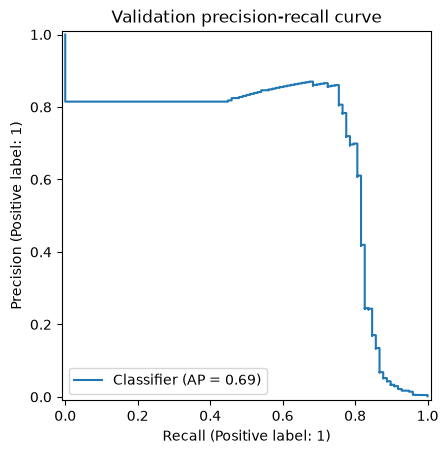

In [11]:
precision, recall, thresholds = precision_recall_curve(y_valid, valid_scores)
# precision and recall have one more point than thresholds
f1_values = (2 * precision[:-1] * recall[:-1]) / (precision[:-1] + recall[:-1] + 1e-12)
if len(thresholds) == 0:
    raise RuntimeError('Could not derive validation thresholds.')
best_idx = int(np.nanargmax(f1_values))
selected_threshold = float(thresholds[best_idx])
print(f'Selected threshold (validation F1 maximum): {selected_threshold:.6f}')
print(f'Validation precision at selected threshold: {precision[best_idx]:.4f}')
print(f'Validation recall at selected threshold: {recall[best_idx]:.4f}')
print(f'Validation F1 at selected threshold: {f1_values[best_idx]:.4f}')

PrecisionRecallDisplay.from_predictions(y_valid, valid_scores)
plt.title('Validation precision-recall curve')
plt.show()

## 8. Final held-out test evaluation

We evaluate once at the threshold selected on validation data. Do not adjust the model or threshold based on these test results; if changes are needed, make them using training/validation data and reserve a fresh test set for a new final estimate.

,metric,value
0,threshold_selected_on_validation,1.000000
1,average_precision_pr_auc,0.757532
2,roc_auc,0.966117
3,precision_at_threshold,0.886364
4,recall_at_threshold,0.787879
5,f1_at_threshold,0.834225
6,test_rows,56962.000000
7,test_fraud_count,99.000000


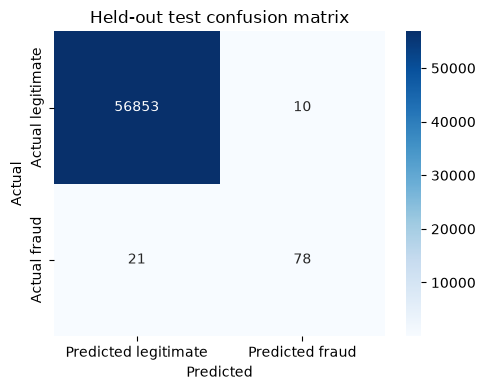

              precision    recall  f1-score   support

  Legitimate       1.00      1.00      1.00     56863
       Fraud       0.89      0.79      0.83        99

    accuracy                           1.00     56962
   macro avg       0.94      0.89      0.92     56962
weighted avg       1.00      1.00      1.00     56962



In [12]:
test_scores = model.predict_proba(X_test)[:, 1]
test_pred = (test_scores >= selected_threshold).astype('int8')

results = {
    'threshold_selected_on_validation': selected_threshold,
    'average_precision_pr_auc': float(average_precision_score(y_test, test_scores)),
    'roc_auc': float(roc_auc_score(y_test, test_scores)),
    'precision_at_threshold': float(precision_score(y_test, test_pred, zero_division=0)),
    'recall_at_threshold': float(recall_score(y_test, test_pred, zero_division=0)),
    'f1_at_threshold': float(f1_score(y_test, test_pred, zero_division=0)),
    'test_rows': int(len(y_test)),
    'test_fraud_count': int(y_test.sum()),
}
results_df = pd.DataFrame({'metric': list(results.keys()), 'value': list(results.values())})
display(results_df)

cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Predicted legitimate', 'Predicted fraud'],
            yticklabels=['Actual legitimate', 'Actual fraud'])
plt.title('Held-out test confusion matrix')
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.tight_layout()
plt.show()

print(classification_report(y_test, test_pred, target_names=['Legitimate', 'Fraud'], zero_division=0))

## 9. Save the verified run summary

This exports a small metrics file for the repository. Review it before committing; include the run date and package versions in your project notes. Never commit the dataset itself.

In [13]:
import json
from datetime import datetime, timezone

run_summary = {
    'project': 'credit-card-fraud-detection',
    'run_utc': datetime.now(timezone.utc).isoformat(),
    'random_state': RANDOM_STATE,
    'split_sizes': {'train': len(y_train), 'validation': len(y_valid), 'test': len(y_test)},
    'model': 'class-weighted logistic regression with StandardScaler for Time and Amount',
    'threshold_selection': 'maximize F1 on validation split',
    'test_metrics': results,
    'note': 'Educational benchmark only; not production validated.'
}
with open('/content/fraud_detection_metrics.json', 'w') as f:
    json.dump(run_summary, f, indent=2)
print('Saved /content/fraud_detection_metrics.json')
# Optional download from Colab:
# from google.colab import files
# files.download('/content/fraud_detection_metrics.json')

Saved /content/fraud_detection_metrics.json


## 10. Conclusions and next steps

Fill this section after running the notebook:

- **Best validated model:** [record actual model]
- **Selected threshold and rationale:** [record from validation]
- **Held-out test results:** [record actual metrics]
- **Important errors:** [inspect false positives and false negatives]
- **Limitations:** anonymized features, benchmark dataset age/representativeness, no production validation.
- **Next experiment:** compare with a tree-based model using the same split and validation-only model selection.

Do not claim the model is production-ready or that it will generalize to current banking data.